# Predictive Analysis - Classification (Landing Success)

Trains and tunes 5 classifiers (Logistic Regression, SVM, Decision Tree, KNN, Random Forest) with 10-fold GridSearchCV, reports test accuracy and the best model's confusion matrix.

**Outputs:** `models/model_results.txt`, `plots/ml_confusion_matrix.png`

```text
Classification Models
=====================
Landing-success prediction with 4 required + 1 extra model, each tuned
with GridSearchCV:  Logistic Regression / SVM / Decision Tree / KNN / Random Forest
Outputs: models/model_results.txt, plots/ml_confusion_matrix.png
```

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

BASE = os.path.abspath(".")
X = pd.read_csv(os.path.join(BASE, "data", "dataset_part_3.csv"))
Y = X["Class"].to_numpy()
X = X.drop(columns=["Class"])
X = X.select_dtypes(include=[np.number]).fillna(0)

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [2]:
PARAMS = {
    "Logistic Regression": (LogisticRegression(max_iter=2000),
                            {"C": [0.01, 0.1, 1, 10], "penalty": ["l2"], "solver": ["lbfgs"]}),
    "SVM": (SVC(), {"C": [0.5, 1, 10], "gamma": [0.0001, 0.001, "auto", "scale"], "kernel": ["rbf"]}),
    "Decision Tree": (DecisionTreeClassifier(), {"criterion": ["gini", "entropy"],
                      "max_depth": [2 * n for n in range(1, 10)], "random_state": [42]}),
    "KNN": (KNeighborsClassifier(), {"n_neighbors": list(range(1, 11)),
            "weights": ["uniform", "distance"], "metric": ["euclidean", "minkowski"]}),
    "Random Forest (extra)": (RandomForestClassifier(random_state=42),
                              {"n_estimators": [100, 300], "max_depth": [None, 10, 20]}),
}

In [3]:
results, best_models = [], {}
log = []
for name, (est, grid) in PARAMS.items():
    gs = GridSearchCV(est, grid, cv=10, n_jobs=-1)
    gs.fit(X_train, Y_train)
    best = gs.best_estimator_
    acc = best.score(X_test, Y_test)
    ypred = best.predict(X_test)
    best_models[name] = best
    results.append({"Model": name, "Best CV Score": round(gs.best_score_, 4),
                    "Test Accuracy": round(acc, 4), "Params": str(gs.best_params_)})
    log.append(f"\n{name}  best_params={gs.best_params_}")
    log.append(classification_report(Y_test, ypred, zero_division=0))

C:\Users\15838\.workbuddy\binaries\python\envs\default\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


                Model  Best CV Score  Test Accuracy                                                           Params
  Logistic Regression         0.8036         0.7778                    {'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}
                  SVM         0.8464         0.8333                     {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
        Decision Tree         0.8071         0.8889     {'criterion': 'entropy', 'max_depth': 2, 'random_state': 42}
                  KNN         0.8607         0.8333 {'metric': 'euclidean', 'n_neighbors': 7, 'weights': 'distance'}
Random Forest (extra)         0.7786         0.7778                         {'max_depth': None, 'n_estimators': 300}

BEST MODEL: Decision Tree
Confusion matrix:
 [[ 5  1]
 [ 1 11]]
Saved -> C:\Users\15838\WorkBuddy\2026-10-29-14-12-57\spacex-capstone\models\model_results.txt


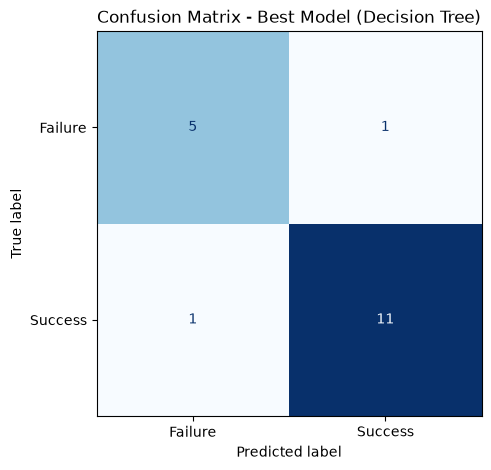

In [4]:
best_name = max(results, key=lambda r: r["Test Accuracy"])["Model"]
best_model = best_models[best_name]
yhat = best_model.predict(X_test)
cm = confusion_matrix(Y_test, yhat)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=["Failure", "Success"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion Matrix - Best Model ({best_name})")
plt.savefig(os.path.join(BASE, "plots", "ml_confusion_matrix.png"), bbox_inches="tight", dpi=150)

out = os.path.join(BASE, "models", "model_results.txt")
os.makedirs(os.path.dirname(out), exist_ok=True)
with open(out, "w", encoding="utf-8") as f:
    f.write(pd.DataFrame(results).to_string(index=False))
    f.write("\n\nBEST MODEL: " + best_name)
    f.write("\n".join(log))
print(pd.DataFrame(results).to_string(index=False))
print("\nBEST MODEL:", best_name)
print("Confusion matrix:\n", cm)
print("Saved ->", out)